###Mount Drive


In [ ]:
from google.colab import drive
import os
import shutil

# Ensure the mount point is clean
if os.path.exists('/content/drive') and os.path.isdir('/content/drive'):
    # Attempt to unmount first
    try:
        !fusermount -u /content/drive
        print("Successfully unmounted /content/drive (if mounted).")
    except Exception as e:
        print(f"Could not unmount /content/drive: {e}")

    # Remove any remaining files or directories inside /content/drive
    for item in os.listdir('/content/drive'):
        item_path = os.path.join('/content/drive', item)
        try:
            if os.path.isfile(item_path) or os.path.islink(item_path):
                os.remove(item_path)
            elif os.path.isdir(item_path):
                shutil.rmtree(item_path)
            print(f"Removed {item_path}")
        except Exception as e:
            print(f"Error removing {item_path}: {e}")

drive.mount('/content/drive', force_remount=True)

Successfully unmounted /content/drive (if mounted).
Mounted at /content/drive


###OLD

In [ ]:
import os
import shutil

FRAMES_ROOT = "/content/drive/MyDrive/3D_organ_Reconstruction/dataset/small_intestine/SampleFrame"
DEPTH_ROOT  = "/content/drive/MyDrive/3D_organ_Reconstruction/dataset/small_intestine/PixelwiseDepths"

def flatten_folder(root):
    inner = os.path.join(root, os.listdir(root)[0])
    if os.path.isdir(inner):
        for f in os.listdir(inner):
            shutil.move(os.path.join(inner, f), root)
        os.rmdir(inner)

# Flatten frames and depth
flatten_folder(FRAMES_ROOT)
flatten_folder(DEPTH_ROOT)

print("Frames count:", len(os.listdir(FRAMES_ROOT)))
print("Depth count:", len(os.listdir(DEPTH_ROOT)))


Frames count: 649
Depth count: 12559


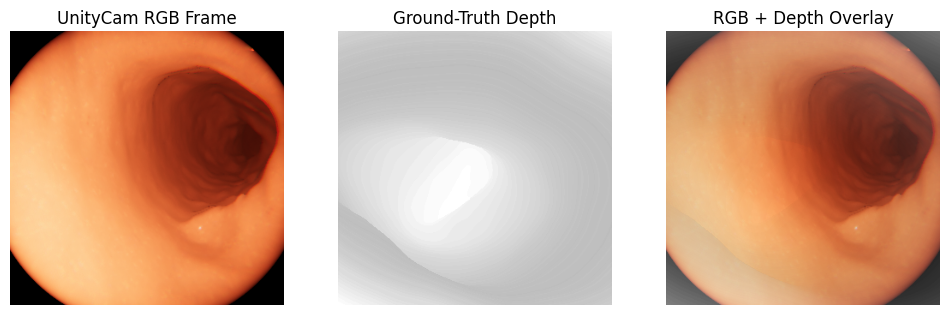

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

BASE = "/content/drive/MyDrive/3D_organ_Reconstruction/dataset/small_intestine"
FRAME_DIR = os.path.join(BASE, "SampleFrame")
DEPTH_DIR = os.path.join(BASE, "PixelwiseDepths")

# Pick the SAME index for both
frame_files = sorted(os.listdir(FRAME_DIR))
depth_files = sorted(os.listdir(DEPTH_DIR))

idx = 100  # arbitrary, safe index

# Load RGB
rgb = cv2.imread(os.path.join(FRAME_DIR, frame_files[idx]))
rgb = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)

# Load depth (usually 16-bit or float)
depth = cv2.imread(os.path.join(DEPTH_DIR, depth_files[idx]), cv2.IMREAD_UNCHANGED)
depth_norm = (depth - depth.min()) / (depth.max() - depth.min())

# Visualize
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(rgb)
plt.title("UnityCam RGB Frame")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(depth_norm, cmap="inferno")
plt.title("Ground-Truth Depth")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(rgb)
plt.imshow(depth_norm, cmap="inferno", alpha=0.5)
plt.title("RGB + Depth Overlay")
plt.axis("off")

plt.show()


Columns: ['tX', 'tY', 'tZ', 'rX', 'rY', 'rZ', 'rW', 'time(s)']
Total poses: 12552
Possible position columns: ['tX', 'tY', 'tZ', 'rX', 'rY', 'rZ']


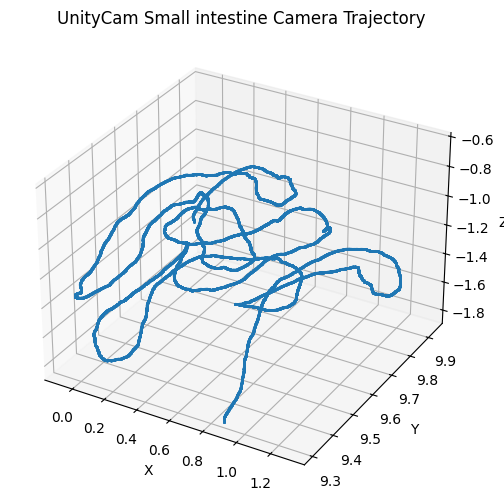

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

POSE_FILE = "/content/drive/MyDrive/3D_organ_Reconstruction/dataset/small_intestine/intestine_position_rotation.csv"

# Load CSV
poses = pd.read_csv(POSE_FILE)

print("Columns:", poses.columns.tolist())
print("Total poses:", len(poses))

# Try common naming (x, y, z)
pos_cols = [c for c in poses.columns if 'x' in c.lower() or 'y' in c.lower() or 'z' in c.lower()]
print("Possible position columns:", pos_cols)

# Assume first three are position (we verify visually)
pos = poses.iloc[:, 0:3].values

# Plot camera trajectory
fig = plt.figure(figsize=(6,6))
ax = fig.add_subplot(111, projection='3d')

ax.plot(pos[:,0], pos[:,1], pos[:,2], '-o', markersize=1)
ax.set_title("UnityCam Small intestine Camera Trajectory")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")

plt.show()


In [ ]:
import numpy as np
import os

CALIB_FILE = "/content/drive/MyDrive/3D_organ_Reconstruction/dataset/small_intestine/cam.txt"

# Check if the directory exists and list its contents to help debug
calib_dir = os.path.dirname(CALIB_FILE)
if not os.path.exists(calib_dir):
    print(f"Error: Calibration directory not found at {calib_dir}")
else:
    print(f"Contents of {calib_dir}: {os.listdir(calib_dir)}")

# List to store all extracted float values
all_float_values = []

with open(CALIB_FILE, "r") as f:
    for line in f:
        stripped_line = line.strip()
        if not stripped_line: # Skip empty lines
            continue

        # Attempt to extract a float value from the line
        # Common formats: "key: value", "value", "value, value, ..."
        try:
            # Try splitting by ':' and taking the second part
            if ':' in stripped_line:
                value_str = stripped_line.split(':', 1)[1].strip()
                all_float_values.append(float(value_str))
            else:
                # If no ':', try to split by ',' and parse each part
                for val_part in stripped_line.split(','):
                    cleaned_val_part = val_part.strip()
                    if cleaned_val_part: # Ensure it's not an empty string
                        all_float_values.append(float(cleaned_val_part))
        except ValueError:
            # If conversion fails, print a warning and skip this part of the line
            print(f"Warning: Could not parse '{stripped_line}' as a float or contains non-numeric parts. Skipping.")
            continue

# We expect 9 values for a 3x3 intrinsic matrix (fx, 0, cx, 0, fy, cy, 0, 0, 1)
# Assuming the first 9 meaningful floats are the intrinsic matrix.
if len(all_float_values) >= 9:
    K = np.array(all_float_values[:9]).reshape(3, 3)
    fx = K[0,0]
    fy = K[1,1]
    cx = K[0,2]
    cy = K[1,2]

    print("Camera Intrinsic Matrix:\n", K)
    print("fx, fy, cx, cy:", fx, fy, cx, cy)
else:
    print(f"Error: Expected at least 9 intrinsic parameters, but found only {len(all_float_values)} in '{CALIB_FILE}'.")
    # Set K to an identity matrix and placeholder values for fx, fy, cx, cy to prevent further errors.
    K = np.eye(3)
    fx, fy, cx, cy = K[0,0], K[1,1], K[0,2], K[1,2]

Contents of /content/drive/MyDrive/3D_organ_Reconstruction/dataset/small_intestine: ['Pixelwise Depths.zip', 'intestine_position_rotation.csv', 'Frames', 'PixelwiseDepths', 'SampleFrame', 'Frames.zip', 'cam.txt']
Error: Expected at least 9 intrinsic parameters, but found only 7 in '/content/drive/MyDrive/3D_organ_Reconstruction/dataset/small_intestine/cam.txt'.


Using K from previous cell.
Depth shape: (320, 320)


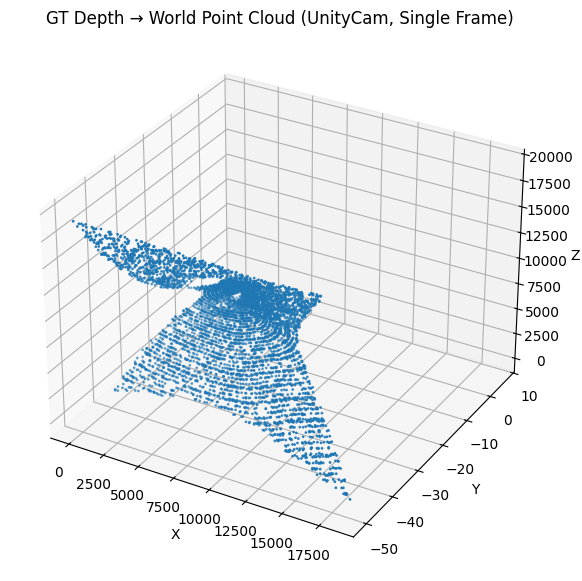

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation as R

# -------- Paths --------
BASE = "/content/drive/MyDrive/3D_organ_Reconstruction/dataset/small_intestine"
DEPTH_DIR = f"{BASE}/PixelwiseDepths"
FRAME_DIR = f"{BASE}/SampleFrame"
POSE_FILE = "/content/drive/MyDrive/3D_organ_Reconstruction/dataset/small_intestine/intestine_position_rotation.csv"
CALIB_FILE = "/content/drive/MyDrive/3D_organ_Reconstruction/dataset/small_intestine/cam.txt"

# -------- Load intrinsics --------
# K, fx, fy, cx, cy were already computed in the previous cell (1apAz2z7NpNf).
# We will use the K from the previous cell, which is currently an identity matrix
# if not enough parameters were found in cam.txt. If cam.txt is fixed, this K
# will contain the correct intrinsics. If you want to re-parse it here with the same
# robust logic, that would be an option, but for now, we'll use the one already in scope.

# Check if K is already defined and has the expected shape (3,3)
if 'K' in locals() and isinstance(K, np.ndarray) and K.shape == (3,3):
    print("Using K from previous cell.")
else:
    print("K not found or malformed. Attempting to load from CALIB_FILE using robust parsing.")
    # Reimplement robust loading for K if it wasn't correctly loaded before
    all_float_values_local = []
    with open(CALIB_FILE, "r") as f:
        for line in f:
            stripped_line = line.strip()
            if not stripped_line: # Skip empty lines
                continue
            try:
                if ':' in stripped_line:
                    value_str = stripped_line.split(':', 1)[1].strip()
                    all_float_values_local.append(float(value_str))
                else:
                    for val_part in stripped_line.split(','):
                        cleaned_val_part = val_part.strip()
                        if cleaned_val_part:
                            all_float_values_local.append(float(cleaned_val_part))
            except ValueError:
                print(f"Warning (in cell 5mah3aAOOgqk): Could not parse '{stripped_line}' as a float or contains non-numeric parts. Skipping.")
                continue

    if len(all_float_values_local) >= 9:
        K = np.array(all_float_values_local[:9]).reshape(3, 3)
        print("K successfully loaded using robust parsing in this cell.")
    else:
        print(f"Error (in cell 5mah3aAOOgqk): Expected at least 9 intrinsic parameters, but found only {len(all_float_values_local)} in '{CALIB_FILE}'. Setting K to identity.")
        K = np.eye(3)

fx, fy, cx, cy = K[0,0], K[1,1], K[0,2], K[1,2]

# -------- Load pose --------
poses = pd.read_csv(POSE_FILE)
idx = 100

t = poses.loc[idx, ['tX','tY','tZ']].values
q = poses.loc[idx, ['rX','rY','rZ','rW']].values
R_wc = R.from_quat(q).as_matrix()

# -------- Load depth (robustly) --------
depth_raw = cv2.imread(
    os.path.join(DEPTH_DIR, sorted(os.listdir(DEPTH_DIR))[idx]),
    cv2.IMREAD_UNCHANGED
)

# If depth has multiple channels, take first one
if depth_raw.ndim == 3:
    depth = depth_raw[:,:,0].astype(np.float32)
else:
    depth = depth_raw.astype(np.float32)

h, w = depth.shape
print("Depth shape:", depth.shape)

# -------- Back-project --------
ys, xs = np.meshgrid(np.arange(h), np.arange(w), indexing='ij')
Z = depth
X = (xs - cx) * Z / fx
Y = (ys - cy) * Z / fy

points_cam = np.stack((X, Y, Z), axis=-1).reshape(-1,3)

# -------- Transform to world --------
points_world = (R_wc @ points_cam.T).T + t

# -------- Subsample --------
pts = points_world[np.random.choice(len(points_world), 8000, replace=False)]

# -------- Visualize --------
fig = plt.figure(figsize=(7,7))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(pts[:,0], pts[:,1], pts[:,2], s=1)

ax.set_title("GT Depth → World Point Cloud (UnityCam, Single Frame)")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")

plt.show()

In [ ]:
with open(CALIB_FILE) as f:
    print(f.read())


fx: 156.0418
fy: 155.7529
cx: 178.560
cy: 181.8043
skew: 0
k1: -0.2486
k2: 0.0614



In [ ]:
fx = 156.0418
fy = 155.7529
cx = 178.560
cy = 181.8043

K = np.array([
    [fx, 0,  cx],
    [0,  fy, cy],
    [0,  0,  1]
], dtype=np.float32)

print("Camera intrinsics:")
print(K)


Camera intrinsics:
[[156.0418   0.     178.56  ]
 [  0.     155.7529 181.8043]
 [  0.       0.       1.    ]]


In [ ]:
print("XYZ min:", pts.min(axis=0))
print("XYZ max:", pts.max(axis=0))


XYZ min: [  0.8777508 -50.659225   -1.780831 ]
XYZ max: [1.84448778e+04 6.34077500e+00 1.90782192e+04]


In [ ]:
import os
import numpy as np
import cv2
import pandas as pd
from scipy.spatial.transform import Rotation as R

# Ensure necessary variables are defined for the loop
# DEPTH_DIR, POSE_FILE, fx, fy, cx, cy are expected to be available from previous cells.

# Define depth_files and indices to fix NameError
depth_files = sorted(os.listdir(DEPTH_DIR))
poses = pd.read_csv(POSE_FILE) # Re-read poses to ensure it's fresh and available
indices = range(100, min(len(depth_files), len(poses))) # Ensure indices are within bounds

all_points = []

for idx in indices:
    depth_raw = cv2.imread(
        os.path.join(DEPTH_DIR, depth_files[idx]),
        cv2.IMREAD_UNCHANGED
    )

    depth = depth_raw[:,:,0].astype(np.float32) if depth_raw.ndim == 3 else depth_raw.astype(np.float32)

    h, w = depth.shape
    ys, xs = np.meshgrid(np.arange(h), np.arange(w), indexing='ij')

    Z = depth
    X = (xs - cx) * Z / fx
    Y = (ys - cy) * Z / fy

    points_cam = np.stack((X, Y, Z), axis=-1).reshape(-1,3)

    # 🔑 SUBSAMPLE BEFORE FUSION
    sample_idx = np.random.choice(len(points_cam), 2000, replace=False)
    points_cam = points_cam[sample_idx]

    t = poses.loc[idx, ['tX','tY','tZ']].values
    q = poses.loc[idx, ['rX','rY','rZ','rW']].values
    R_wc = R.from_quat(q).as_matrix()

    points_world = (R_wc @ points_cam.T).T + t
    all_points.append(points_world.astype(np.float32))

    if idx % 200 == 0:
        print(f"Processed frame {idx}")

Processed frame 200
Processed frame 400
Processed frame 600
Processed frame 800
Processed frame 1000
Processed frame 1200
Processed frame 1400
Processed frame 1600
Processed frame 1800
Processed frame 2000
Processed frame 2200
Processed frame 2400
Processed frame 2600
Processed frame 2800
Processed frame 3000
Processed frame 3200
Processed frame 3400
Processed frame 3600
Processed frame 3800
Processed frame 4000
Processed frame 4200
Processed frame 4400
Processed frame 4600
Processed frame 4800
Processed frame 5000
Processed frame 5200
Processed frame 5400
Processed frame 5600
Processed frame 5800
Processed frame 6000
Processed frame 6200
Processed frame 6400
Processed frame 6600
Processed frame 6800
Processed frame 7000
Processed frame 7200
Processed frame 7400
Processed frame 7600
Processed frame 7800
Processed frame 8000
Processed frame 8200
Processed frame 8400
Processed frame 8600
Processed frame 8800
Processed frame 9000
Processed frame 9200
Processed frame 9400
Processed frame 9

In [ ]:
points_fused = np.vstack(all_points)

final_idx = np.random.choice(len(points_fused), 12000, replace=False)
pts = points_fused[final_idx]


In [ ]:
print("Total fused points:", len(points_fused))
print("XYZ min:", points_fused.min(axis=0))
print("XYZ max:", points_fused.max(axis=0))
print("Any NaNs:", np.isnan(points_fused).any())


Total fused points: 24904000
XYZ min: [-209.67392 -388.72083 -441.281  ]
XYZ max: [321.742   119.27418 274.41748]
Any NaNs: False


In [ ]:
np.savez(
    "/content/drive/MyDrive/3D_organ_Reconstruction/fused_intestine_pc.npz",
    points=points_fused
)


In [ ]:
def save_ply(filename, points):
    with open(filename, 'w') as f:
        f.write("ply\nformat ascii 1.0\n")
        f.write(f"element vertex {len(points)}\n")
        f.write("property float x\nproperty float y\nproperty float z\n")
        f.write("end_header\n")
        for p in points:
            f.write(f"{p[0]} {p[1]} {p[2]}\n")

save_ply(
    "/content/drive/MyDrive/3D_organ_Reconstruction/fused_intestine_pc.ply",
    pts
)


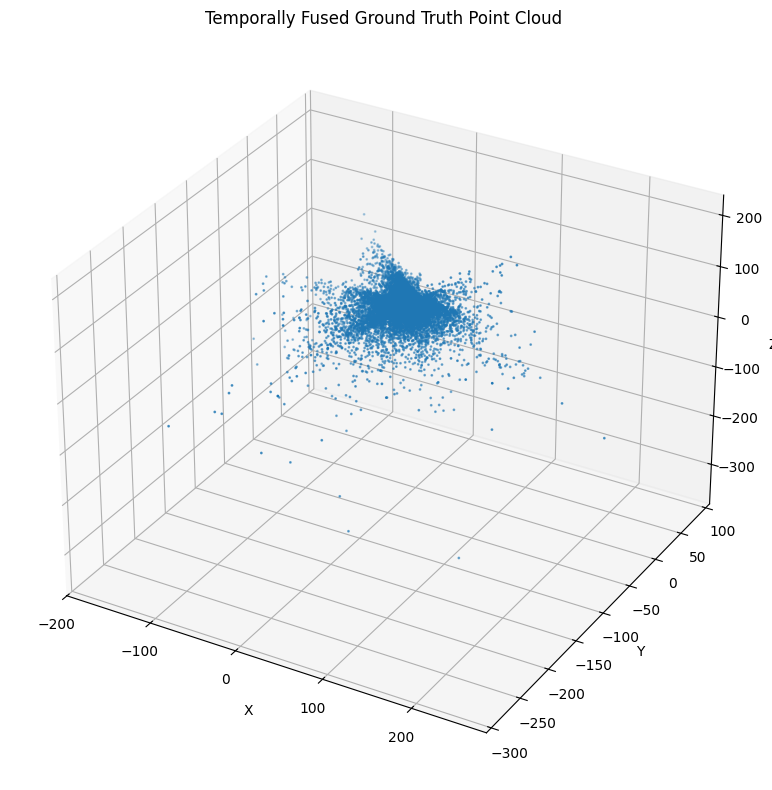

In [ ]:
fig = plt.figure(figsize=(8,8))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(pts[:,0], pts[:,1], pts[:,2], s=1)

ax.set_title("Temporally Fused Ground Truth Point Cloud")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")

plt.tight_layout()
plt.savefig("/content/drive/MyDrive/3D_organ_Reconstruction/fused_pc_visual.png", dpi=300)
plt.show()


STEP 9 — VOXEL DOWNSAMPLING (DO THIS FIRST)

In [ ]:
# ----- Voxel downsampling -----
voxel_size = 2.0  # try 2.0 units (adjust later if needed)

# Quantize points into voxels
coords = np.floor(points_fused / voxel_size)

# Find unique voxels
_, unique_indices = np.unique(coords, axis=0, return_index=True)

points_voxel = points_fused[unique_indices]

print("After voxel downsampling:", points_voxel.shape)


After voxel downsampling: (573276, 3)


STEP 10 — STATISTICAL OUTLIER REMOVAL

In [ ]:
from sklearn.neighbors import NearestNeighbors

sample = points_voxel

nbrs = NearestNeighbors(n_neighbors=20, algorithm='auto').fit(sample)
distances, _ = nbrs.kneighbors(sample)

mean_dist = distances[:,1:].mean(axis=1)

threshold = mean_dist.mean() + 2.0 * mean_dist.std()

points_clean = sample[mean_dist < threshold]

print("After outlier removal:", points_clean.shape)


After outlier removal: (544503, 3)


STEP 11 — VISUALIZE CLEANED CLOUD

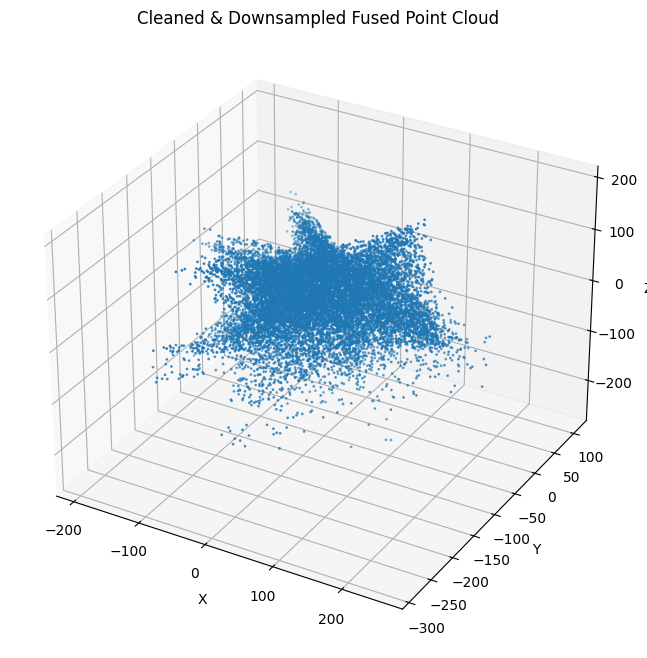

In [ ]:
vis_idx = np.random.choice(len(points_clean), 15000, replace=False)
pts_clean_vis = points_clean[vis_idx]

fig = plt.figure(figsize=(8,8))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    pts_clean_vis[:,0],
    pts_clean_vis[:,1],
    pts_clean_vis[:,2],
    s=1
)

ax.set_title("Cleaned & Downsampled Fused Point Cloud")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")

plt.show()


In [ ]:
#SAVE CLEANED POINT CLOUD

np.savez(
    "/content/drive/MyDrive/3D_organ_Reconstruction/fused_intestine_pc_clean.npz",
    points=points_clean
)


(STEP A): NORMAL ESTIMATION

In [ ]:
!pip install open3d


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 447.7/447.7 MB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 81.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.8/139.8 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 67.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 51.3 MB/s eta 0:00:00
  Attempting uninstall: widgetsnbextension
    Found existing installation: widgetsnbextension 3.6.10
    Uninstalling widgetsnbextension-3.6.10:
      Successfully uninstalled widgetsnbextension-3.6.10
  Attempting uninstall: ipywidgets
    Found existing installation: ipywidgets 7.7.1
    Uninstalling ipywidgets-7.7.1:
      Successfully uninstalled ipywidgets-7.7.1


In [ ]:
import open3d as o3d
import numpy as np


In [ ]:
# Load cleaned point cloud
data = np.load("/content/drive/MyDrive/3D_organ_Reconstruction/fused_intestine_pc_clean.npz")
points_clean = data["points"]

print("Loaded points:", points_clean.shape)


Loaded points: (544503, 3)


In [ ]:
#CREATE OPEN3D POINT CLOUD OBJECT

pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(points_clean)


In [ ]:
#ESTIMATE NORMALS
pcd.estimate_normals(
    search_param=o3d.geometry.KDTreeSearchParamHybrid(
        radius=10.0,   # neighborhood size (important)
        max_nn=30
    )
)


In [ ]:
#ORIENT NORMALS CONSISTENTLY
pcd.orient_normals_consistent_tangent_plane(k=50)


In [ ]:
#QUICK VISUAL CHECK
pcd_vis = pcd.random_down_sample(sampling_ratio=0.02)

o3d.visualization.draw_geometries(
    [pcd_vis],
    window_name="Point Cloud with Normals",
    point_show_normal=True
)


[Open3D WARNING] GLFW Error: Failed to detect any supported platform
[Open3D WARNING] GLFW initialized for headless rendering.
[Open3D WARNING] GLFW Error: OSMesa: Library not found
[Open3D WARNING] Failed to create window
[Open3D WARNING] [DrawGeometries] Failed creating OpenGL window.


In [ ]:
#SAVE POINT CLOUD WITH NORMALS
o3d.io.write_point_cloud(
    "/content/drive/MyDrive/3D_organ_Reconstruction/fused_intestine_pc_with_normals.ply",
    pcd
)

[Open3D WARNING] Write PLY failed: point cloud has 0 points.


False

STEP B: POISSON SURFACE RECONSTRUCTION

In [ ]:
#LOAD POINT CLOUD WITH NORMALS
import open3d as o3d

pcd = o3d.io.read_point_cloud(
    "/content/drive/MyDrive/3D_organ_Reconstruction/fused_intestine_pc_with_normals.ply"
)

print(pcd)


PointCloud with 544503 points.


In [ ]:
mesh, densities = o3d.geometry.TriangleMesh.create_from_point_cloud_poisson(
    pcd,
    depth=9,        # reconstruction depth (controls resolution)
    width=0,
    scale=1.1,
    linear_fit=False
)


In [ ]:
#REMOVE LOW-DENSITY ARTIFACTS
import numpy as np

densities = np.asarray(densities)

density_threshold = np.quantile(densities, 0.02)  # remove lowest 2%
vertices_to_remove = densities < density_threshold
mesh.remove_vertices_by_mask(vertices_to_remove)


In [ ]:
#CLEAN THE MESH
mesh.remove_degenerate_triangles()
mesh.remove_duplicated_triangles()
mesh.remove_duplicated_vertices()
mesh.remove_non_manifold_edges()


TriangleMesh with 2013385 points and 4067721 triangles.

In [ ]:
#VISUALIZE THE MESH
o3d.visualization.draw_geometries(
    [mesh],
    window_name="Poisson Reconstructed Surface"
)


[Open3D WARNING] GLFW initialized for headless rendering.
[Open3D WARNING] GLFW Error: OSMesa: Library not found
[Open3D WARNING] Failed to create window
[Open3D WARNING] [DrawGeometries] Failed creating OpenGL window.


In [ ]:
#CHECK 1 — MESH STATISTICS
import numpy as np

V = np.asarray(mesh.vertices)
F = np.asarray(mesh.triangles)

print("Vertices:", V.shape)
print("Triangles:", F.shape)

print("XYZ min:", V.min(axis=0))
print("XYZ max:", V.max(axis=0))
print("Any NaNs:", np.isnan(V).any())


Vertices: (2013385, 3)
Triangles: (4067721, 3)
XYZ min: [-203.18005371 -279.81652832 -252.76019287]
XYZ max: [282.60314941 112.90600586 199.74365234]
Any NaNs: False


In [ ]:
#CHECK 2 — DENSITY-BASED CROPPING WORKED
print("Mesh is empty:", mesh.is_empty())
print("Watertight:", mesh.is_watertight())
print("Edge manifold:", mesh.is_edge_manifold())


Mesh is empty: False
Watertight: False
Edge manifold: True


In [ ]:
#CHECK 3 — EXPORT & INSPECT LOCALLY
import open3d as o3d
from google.colab import files

# Save the mesh first
mesh_filepath = "/content/drive/MyDrive/3D_organ_Reconstruction/intestine_poisson_mesh.ply"
o3d.io.write_triangle_mesh(mesh_filepath, mesh)
print(f"Mesh saved to {mesh_filepath}")

files.download(mesh_filepath)


Mesh saved to /content/drive/MyDrive/3D_organ_Reconstruction/intestine_poisson_mesh.ply


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

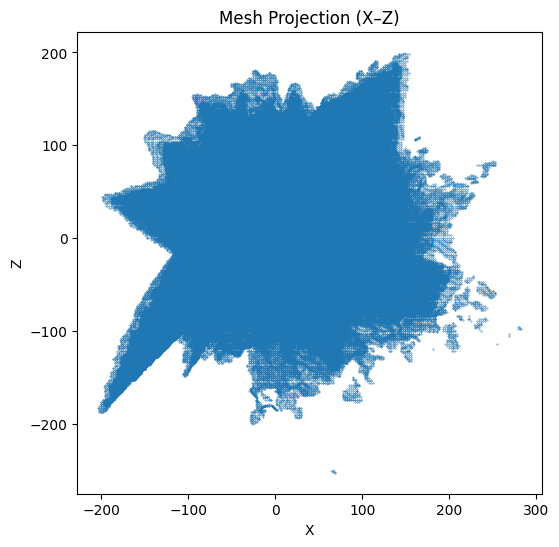

In [ ]:
# 2D PROJECTION CHECK
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.scatter(V[:,0], V[:,2], s=0.1)
plt.xlabel("X")
plt.ylabel("Z")
plt.title("Mesh Projection (X–Z)")
plt.show()


In [ ]:
pcd.orient_normals_consistent_tangent_plane(100)
pcd.normalize_normals()


PointCloud with 544503 points.

In [ ]:
mesh, densities = o3d.geometry.TriangleMesh.create_from_point_cloud_poisson(
    pcd,
    depth=8,
    scale=1.05
)


In [ ]:
densities = np.asarray(densities)
threshold = np.quantile(densities, 0.05)
mesh.remove_vertices_by_mask(densities < threshold)


Redoing Poisson with corrected normals.

In [ ]:
import open3d as o3d
import numpy as np

pcd = o3d.io.read_point_cloud(
    "/content/drive/MyDrive/3D_organ_Reconstruction/Phase3/fused_intestine_pc_with_normals.ply"
)

print(pcd)


PointCloud with 544866 points.


In [ ]:
pcd.estimate_normals(
    search_param=o3d.geometry.KDTreeSearchParamHybrid(
        radius=5.0,
        max_nn=30
    )
)


In [ ]:
pcd.orient_normals_consistent_tangent_plane(100)
pcd.normalize_normals()


PointCloud with 544866 points.

In [ ]:
mesh, densities = o3d.geometry.TriangleMesh.create_from_point_cloud_poisson(
    pcd,
    depth=8,      # reduced from 9
    scale=1.05
)


In [ ]:
densities = np.asarray(densities)
threshold = np.quantile(densities, 0.05)

mesh.remove_vertices_by_mask(densities < threshold)


In [ ]:
bbox = pcd.get_axis_aligned_bounding_box()
mesh = mesh.crop(bbox)


In [ ]:
mesh.remove_degenerate_triangles()
mesh.remove_duplicated_triangles()
mesh.remove_duplicated_vertices()
mesh.remove_non_manifold_edges()


TriangleMesh with 622868 points and 1256312 triangles.

In [ ]:
V = np.asarray(mesh.vertices)
print("Vertices:", V.shape)
print("Triangles:", np.asarray(mesh.triangles).shape)
print("Is empty:", mesh.is_empty())


Vertices: (622868, 3)
Triangles: (1256312, 3)
Is empty: False


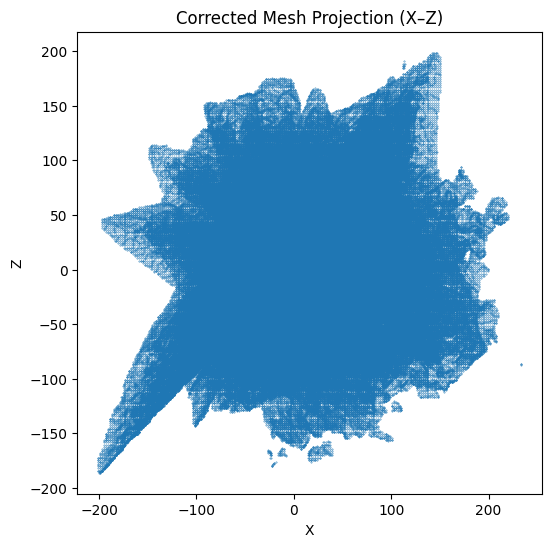

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.scatter(V[:,0], V[:,2], s=0.1)
plt.xlabel("X")
plt.ylabel("Z")
plt.title("Corrected Mesh Projection (X–Z)")
plt.show()


###New

In [ ]:
!pip install opencv-python

In [ ]:
import numpy as np
import cv2
import pandas as pd
import os
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation as R
# -------- Paths --------
BASE = "/content/drive/MyDrive/3D_organ_Reconstruction/dataset/small_intestine"
DEPTH_DIR = f"{BASE}/PixelwiseDepths"
FRAME_DIR = f"{BASE}/SampleFrame"
POSE_FILE = "/content/drive/MyDrive/3D_organ_Reconstruction/dataset/small_intestine/intestine_position_rotation.csv"
CALIB_FILE = "/content/drive/MyDrive/3D_organ_Reconstruction/dataset/small_intestine/cam.txt"
CHK_DIR = f"{BASE}/checkpoints"
os.makedirs(CHK_DIR, exist_ok=True)




Centerline points: (1256, 3)


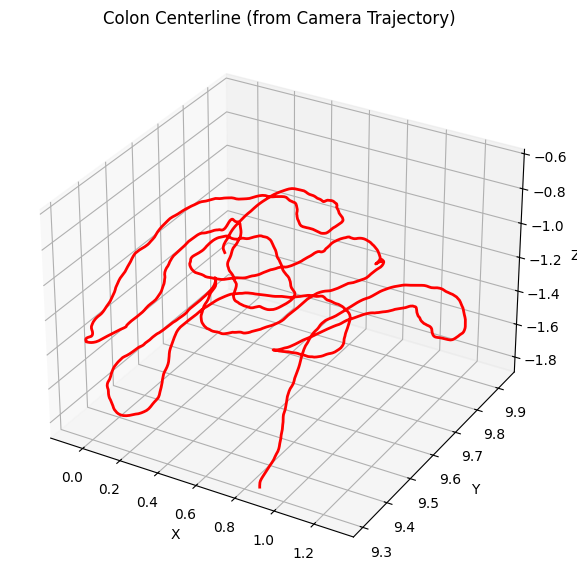

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d


poses = pd.read_csv(POSE_FILE)

# Extract camera positions
centerline = poses[['tX', 'tY', 'tZ']].values

# Smooth trajectory (VERY important)
centerline_smooth = gaussian_filter1d(centerline, sigma=5, axis=0)

# Subsample for stability
centerline_smooth = centerline_smooth[::10]

print("Centerline points:", centerline_smooth.shape)

# Visualize centerline
fig = plt.figure(figsize=(7,7))
ax = fig.add_subplot(111, projection='3d')
ax.plot(centerline_smooth[:,0],
        centerline_smooth[:,1],
        centerline_smooth[:,2],
        '-r', linewidth=2)

ax.set_title("Colon Centerline (from Camera Trajectory)")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
plt.show()


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
from scipy.spatial.transform import Rotation as R

# ----------------------------
# Paths
# ----------------------------
DEPTH_DIR = "/content/depth_frames"
POSE_FILE = "/content/poses.csv"

OUTPUT_FILE = "/content/final_pointcloud.npz"

# ----------------------------
# Camera Intrinsics
# ----------------------------
fx = 156.0418
fy = 155.7529
cx = 178.560
cy = 181.8043

# ----------------------------
# Settings (important)
# ----------------------------
FRAME_STRIDE = 3        # use every 3rd frame
DOWNSAMPLE = 4          # reduce resolution 16x
POINT_SAMPLE = 3000     # max points per frame

# ----------------------------
# Load data
# ----------------------------
poses = pd.read_csv(POSE_FILE)

depth_files = sorted([
    f for f in os.listdir(DEPTH_DIR)
    if f.endswith(".png")
])

print("Total frames:", len(depth_files))

global_points = []

# ----------------------------
# Processing loop
# ----------------------------
for idx in range(0, len(depth_files), FRAME_STRIDE):

    if idx % 100 == 0:
        print("Processing frame:", idx)

    depth_path = os.path.join(DEPTH_DIR, depth_files[idx])

    depth_raw = cv2.imread(depth_path, cv2.IMREAD_UNCHANGED)

    if depth_raw is None:
        continue

    depth = depth_raw[:,:,0] if depth_raw.ndim == 3 else depth_raw
    depth = depth.astype(np.float32)

    # ----------------------------
    # Downsample depth
    # ----------------------------
    depth = depth[::DOWNSAMPLE, ::DOWNSAMPLE]

    h, w = depth.shape

    ys, xs = np.meshgrid(np.arange(h), np.arange(w), indexing='ij')

    Z = depth
    X = (xs - cx/DOWNSAMPLE) * Z / fx
    Y = (ys - cy/DOWNSAMPLE) * Z / fy

    points_cam = np.stack((X, Y, Z), axis=-1).reshape(-1,3)

    # Remove invalid depth
    valid = Z.reshape(-1) > 0
    points_cam = points_cam[valid]

    # ----------------------------
    # Camera pose
    # ----------------------------
    t = poses.loc[idx, ['tX','tY','tZ']].values
    q = poses.loc[idx, ['rX','rY','rZ','rW']].values

    R_wc = R.from_quat(q).as_matrix()

    # ----------------------------
    # Transform to world
    # ----------------------------
    points_world = (R_wc @ points_cam.T).T + t

    # ----------------------------
    # Random sampling
    # ----------------------------
    if points_world.shape[0] > POINT_SAMPLE:

        sample_idx = np.random.choice(
            points_world.shape[0],
            POINT_SAMPLE,
            replace=False
        )

        points_world = points_world[sample_idx]

    global_points.append(points_world)

# ----------------------------
# Merge all points
# ----------------------------
print("\nMerging point clouds...")

global_points = np.vstack(global_points)

print("Total points:", global_points.shape)

# ----------------------------
# Reduce storage
# ----------------------------
global_points = global_points.astype(np.float16)

# ----------------------------
# Save compressed file
# ----------------------------
np.savez_compressed(OUTPUT_FILE, points=global_points)

print("\nSaved point cloud to:")
print(OUTPUT_FILE)

FileNotFoundError: [Errno 2] No such file or directory: '/content/poses.csv'

In [ ]:
import numpy as np
import glob

MAX_POINTS = 150_000   # safe upper limit
points_sampled = []

for f in sorted(glob.glob(f"{CHK_DIR}/points_*.npy")):
    pts = np.load(f)   # load ONE chunk only

    if len(points_sampled) == 0:
        # First chunk
        if len(pts) > MAX_POINTS:
            idx = np.random.choice(len(pts), MAX_POINTS, replace=False)
            points_sampled = pts[idx]
        else:
            points_sampled = pts
    else:
        # Combine with reservoir logic
        combined = np.vstack([points_sampled, pts])

        if len(combined) > MAX_POINTS:
            idx = np.random.choice(len(combined), MAX_POINTS, replace=False)
            points_sampled = combined[idx]
        else:
            points_sampled = combined

    print(f"Processed {f}, current points: {len(points_sampled)}")

points_fused = points_sampled
print("Final fused points:", points_fused.shape)


Processed /content/drive/MyDrive/3D_organ_Reconstruction/dataset/small_intestine/checkpoints/points_5400_5700.npy, current points: 150000
Processed /content/drive/MyDrive/3D_organ_Reconstruction/dataset/small_intestine/checkpoints/points_5700_6000.npy, current points: 150000
Processed /content/drive/MyDrive/3D_organ_Reconstruction/dataset/small_intestine/checkpoints/points_6000_6300.npy, current points: 150000
Final fused points: (150000, 3)


In [ ]:
SAVE_DIR = "/content/drive/MyDrive/3DOrganReconstruction/outputs"

In [ ]:

os.makedirs(SAVE_DIR, exist_ok=True)

np.save(
    f"{SAVE_DIR}/phase3_fused_points.npy",
    points_fused.astype(np.float32)
)

print("✅ Saved fused point cloud")


✅ Saved fused point cloud


In [ ]:
import numpy as np

SAVE_DIR = "/content/drive/MyDrive/3DOrganReconstruction/outputs"

points_fused = np.load(
    f"{SAVE_DIR}/phase3_fused_points.npy",
    mmap_mode="r"   # 🔥 RAM SAFE
)

print("Loaded fused points:", points_fused.shape)

Loaded fused points: (150000, 3)


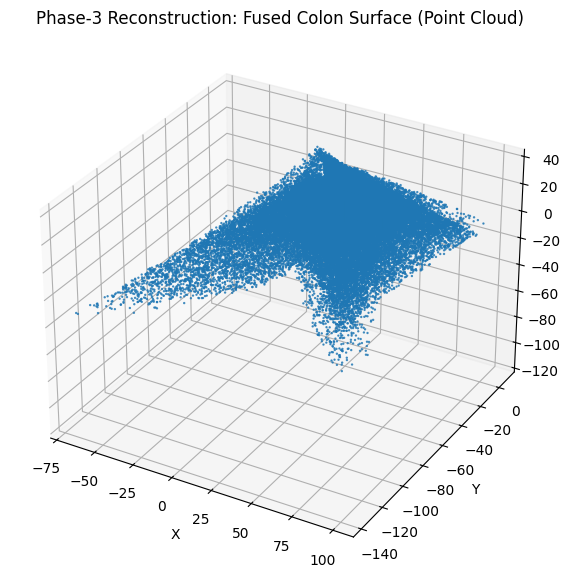

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Sample a safe number of points for visualization
N_VIS = 60000
idx = np.random.choice(points_fused.shape[0], N_VIS, replace=False)

pts = points_fused[idx]

# Plot
fig = plt.figure(figsize=(7,7))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    pts[:,0],
    pts[:,1],
    pts[:,2],
    s=0.5,
    alpha=0.8
)

ax.set_title("Phase-3 Reconstruction: Fused Colon Surface (Point Cloud)")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")

plt.show()

In [ ]:
!pip install numpy==1.26.4 scipy==1.11.4 --no-cache-dir

In [ ]:
import numpy
import scipy

print(numpy.__version__)
print(scipy.__version__)

1.26.4
1.11.4


Centerline points: (1256, 3)


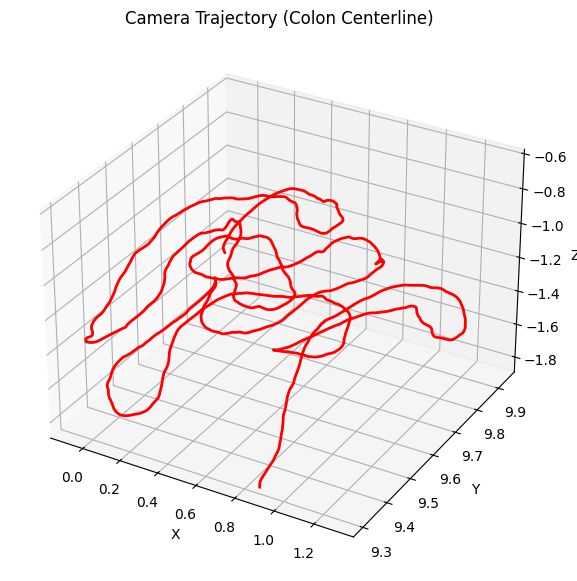

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
import os

# Redefine BASE and POSE_FILE here to ensure they are available
BASE = "/content/drive/MyDrive/3D_organ_Reconstruction/dataset/small_intestine"
POSE_FILE = os.path.join(BASE, "intestine_position_rotation.csv")

poses = pd.read_csv(POSE_FILE)

# Extract camera translation (trajectory)
centerline = poses[['tX','tY','tZ']].values

# Smooth the trajectory to remove jitter
centerline_smooth = gaussian_filter1d(centerline, sigma=5, axis=0)

# Subsample to reduce density
centerline_smooth = centerline_smooth[::10]

print("Centerline points:", centerline_smooth.shape)

# visualize
fig = plt.figure(figsize=(7,7))
ax = fig.add_subplot(111, projection='3d')

ax.plot(
    centerline_smooth[:,0],
    centerline_smooth[:,1],
    centerline_smooth[:,2],
    '-r',
    linewidth=2
)

ax.set_title("Camera Trajectory (Colon Centerline)")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")

plt.show()

In [ ]:
import numpy as np
import os

SAVE_DIR = "/content/drive/MyDrive/3DOrganReconstruction/outputs"
os.makedirs(SAVE_DIR, exist_ok=True)

np.save(
    f"{SAVE_DIR}/phase3_centerline.npy",
    centerline_smooth.astype(np.float32)
)

print("✅ Centerline saved successfully")

✅ Centerline saved successfully


In [ ]:
centerline_smooth = np.load(
    "/content/drive/MyDrive/3DOrganReconstruction/outputs/phase3_centerline.npy"
)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Load centerline (safe in case runtime restarted)
centerline = np.load(
    "/content/drive/MyDrive/3DOrganReconstruction/outputs/phase3_centerline.npy"
)

radius = 0.15        # colon radius (adjustable)
circle_pts = 20      # points per ring

rings = []

for p in centerline:
    theta = np.linspace(0, 2*np.pi, circle_pts)

    # simple circular ring around the point
    x = p[0] + radius * np.cos(theta)
    y = p[1] + radius * np.sin(theta)
    z = np.ones_like(theta) * p[2]

    ring = np.vstack([x, y, z]).T
    rings.append(ring)

rings = np.array(rings)

print("Rings shape:", rings.shape)

Rings shape: (1256, 20, 3)


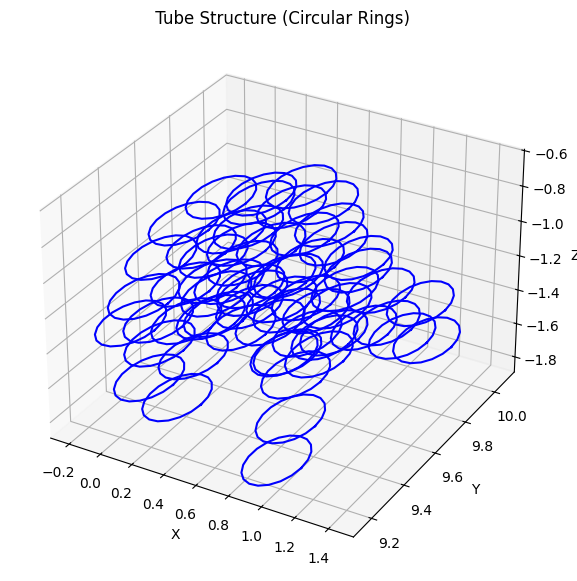

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(7,7))
ax = fig.add_subplot(111, projection='3d')

# Plot a subset so it stays fast
for i in range(0, len(rings), 20):
    ring = rings[i]
    ax.plot(ring[:,0], ring[:,1], ring[:,2], color='blue')

ax.set_title(" Tube Structure (Circular Rings)")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")

plt.show()

In [ ]:
import numpy as np
import open3d as o3d
import os

# Convert rings to vertices
vertices = rings.reshape(-1,3)

n_rings = rings.shape[0]
pts_per_ring = rings.shape[1]

triangles = []

# Connect rings to form surface
for i in range(n_rings-1):
    for j in range(pts_per_ring-1):

        v1 = i*pts_per_ring + j
        v2 = v1 + 1
        v3 = (i+1)*pts_per_ring + j
        v4 = v3 + 1

        triangles.append([v1, v2, v3])
        triangles.append([v2, v4, v3])

triangles = np.array(triangles)

# Create mesh
mesh = o3d.geometry.TriangleMesh()
mesh.vertices = o3d.utility.Vector3dVector(vertices)
mesh.triangles = o3d.utility.Vector3iVector(triangles)

mesh.compute_vertex_normals()

# Save mesh
SAVE_DIR = "/content/drive/MyDrive/3DOrganReconstruction/outputs"
os.makedirs(SAVE_DIR, exist_ok=True)

mesh_path = f"{SAVE_DIR}/phase3_colon_tube_mesh.ply"
o3d.io.write_triangle_mesh(mesh_path, mesh)

print("✅ Colon mesh saved at:", mesh_path)

✅ Colon mesh saved at: /content/drive/MyDrive/3DOrganReconstruction/outputs/phase3_colon_tube_mesh.ply
